# ЛР №1. Запуск открытой модели text-to-image

**Вариант 3** — концепт постера научной выставки.  
Изменяемый фактор: ограничение `no text` и чистая композиция.

**Репозиторий:** https://github.com/ykvnkm/ai-in-creative-industries

| | |
| --- | --- |
| Модель | `stabilityai/sd-turbo` |
| Ревизия | `b261bac6fd2cf515557d5d0707481eafa0485ec2` |
| Артефакты | `artifacts/run_001/`, `artifacts/run_002/` — PNG + manifest.json |
| Критерий приёмки | `exact_sha256_match: true` и отсутствие псевдотекста |

Ноутбук выполняется сверху вниз и сам создаёт структуру, `environment.txt`,
единый конфиг, два запуска, манифесты и сравнение контрольных сумм. Сохранённые
выходы ячеек являются протоколом фактического выполнения.


## 1. Цель, постановка задачи и критерии успешности

**Цель:** получить воспроизводимый результат text-to-image по варианту 3,
зафиксировать происхождение артефактов и объяснить границы совпадения.

**Задача варианта 3:** создать концепт постера научной выставки; управляемое
решение — `no text` и чистая композиция; обязательная проверка — точный повтор
без изменения конфигурации; артефакты — PNG, JSON и таблица проверки.

| | Критерий | Проверка |
| --- | --- | --- |
| К1 | PNG и JSON создаются одним вызовом | ячейка «запуск 1» |
| К2 | PNG открывается, размер 512 × 512, режим RGB | ячейка «валидация» |
| К3 | JSON валиден и совпадает с единым конфигом | автоматические `assert` |
| К4 | SHA-256 содержит 64 hex-символа | независимый пересчёт |
| К5 | Повтор даёт тот же SHA-256 | `sha256_comparison.json` |
| К6 | Нет текста, логотипа и людей | визуальный анализ результата |
| К7 | Типовая ошибка воспроизведена и исправление объяснено | отдельная ячейка |


In [1]:
# Детерминизм CUDA нужно включить до импорта torch.
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")

# Связка из методички diffusers==0.40.0 + transformers<5 неразрешима:
# их диапазоны huggingface-hub не пересекаются. Сохраняем Diffusers 0.40.0
# и используем совместимый Transformers 5.x.
NEED = 'diffusers==0.40.0 transformers>=5,<6 accelerate>=1.2,<2 safetensors>=0.5,<1 Pillow>=11,<13'

def versions_ok():
    try:
        import diffusers, transformers
    except ImportError:
        return False
    return (diffusers.__version__ == "0.40.0"
            and int(transformers.__version__.split(".")[0]) >= 5)

if versions_ok():
    import diffusers, transformers
    print(f"нужные версии уже стоят: diffusers {diffusers.__version__}, "
          f"transformers {transformers.__version__}")
else:
    !pip install -q {NEED}
    print("установка завершена; при необходимости перезапустите среду")


C:\DONSTU\babka\ai-creative-lab01\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


нужные версии уже стоят: diffusers 0.40.0, transformers 5.17.0


In [2]:
# Шаг 1: структура проекта и фиксация окружения.
import json, platform, subprocess, sys
from pathlib import Path
import torch, diffusers, transformers

for d in ["configs", "artifacts", "reports"]:
    Path(d).mkdir(exist_ok=True)

Path("reports/environment.txt").write_text(
    subprocess.run([sys.executable, "-m", "pip", "freeze"],
                   capture_output=True, text=True).stdout,
    encoding="utf-8")

print("python       ", platform.python_version())
print("platform     ", platform.platform())
print("torch        ", torch.__version__)
print("diffusers    ", diffusers.__version__)
print("transformers ", transformers.__version__)
print("cuda_available", torch.cuda.is_available())
print("пакетов в environment.txt:",
      len(Path("reports/environment.txt").read_text(encoding="utf-8").splitlines()))


python        3.11.16
platform      Windows-10-10.0.26200-SP0
torch         2.5.1+cpu
diffusers     0.40.0
transformers  5.17.0
cuda_available False
пакетов в environment.txt: 74


## 2. Prompt, ограничения данных и лицензия

Единственные входные данные — авторский prompt. Персональные данные, реальные
лица, товарные знаки, закрытые брифы и клиентские материалы не использовались.

| Элемент | Формулировка | Назначение |
| --- | --- | --- |
| Объект | `luminous translucent crystal` | метафора исследуемого объекта |
| Среда | `midnight-blue pedestal`, orbital arcs, particles | выставочное пространство без реальной площадки |
| Палитра | blue and warm amber | холодный фон и тёплый акцент |
| Композиция | centered, negative space, full-bleed, borderless | чистая структура без типографических зон |
| Ограничения | `no text or typography`, no logo, no people | критерий варианта и безопасность |
| Граница смысла | `not a diagram or documentary evidence` | концепт не выдается за научный факт |

**Почему не используется слово `poster`.** В пилоте оно вызвало псевдотекст внизу
кадра. Финальная формулировка `square key visual` была выбрана до контрольных
запусков и удерживает контекст афиши без провокации типографики.

**Лицензия.** Закреплённая ревизия содержит Stability AI Community License;
копия лежит в `assignment/model_LICENSE.md`. Использование учебное и локальное,
веса не коммитятся. Pipeline этой модели загружается без safety checker, поэтому
результат проверяется вручную и не разворачивается как публичный сервис.


In [3]:
# Шаг 2: все параметры эксперимента — в одном файле.
CONFIG = {
    "variant": 3,
    "variant_context": "концепт постера научной выставки",
    "variant_factor": "ограничение no text и чистая композиция",
    "model_id": "stabilityai/sd-turbo",
    "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
    "prompt": (
        "text-free square key visual for a science exhibition, "
        "luminous translucent crystal floating above midnight-blue pedestal, "
        "orbital light arcs and amber particles, blue and warm amber palette, "
        "centered clean composition, generous negative space, "
        "full-bleed borderless abstract artwork, no frame, no text or typography, "
        "no logo or watermark, no people, not a diagram or documentary evidence"
    ),
    "seed": 30032026,
    "num_inference_steps": 1,
    "guidance_scale": 0.0,
    "height": 512,
    "width": 512,
}
Path("configs/run_config.json").write_text(
    json.dumps(CONFIG, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))


{
  "variant": 3,
  "variant_context": "концепт постера научной выставки",
  "variant_factor": "ограничение no text и чистая композиция",
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "text-free square key visual for a science exhibition, luminous translucent crystal floating above midnight-blue pedestal, orbital light arcs and amber particles, blue and warm amber palette, centered clean composition, generous negative space, full-bleed borderless abstract artwork, no frame, no text or typography, no logo or watermark, no people, not a diagram or documentary evidence",
  "seed": 30032026,
  "num_inference_steps": 1,
  "guidance_scale": 0.0,
  "height": 512,
  "width": 512
}


## 3. Среда и параметры

Фактические версии и устройство напечатаны выше и дублируются в каждом манифесте.
Полная `revision` фиксирует конкретное состояние весов; одно имя репозитория
недостаточно, поскольку оно может указывать на обновлённый снимок.

CPU выбран фактически установленной сборкой PyTorch. На CPU используется `float32`,
CPU Generator с тем же seed создаётся для каждого запуска, число потоков закреплено
равным единице, а детерминированные алгоритмы включены.

Команда из методички с `transformers>=4.51,<5` конфликтует с Diffusers 0.40.0
по требованиям к `huggingface-hub`. Минимальная коррекция — сохранить требуемый
Diffusers и перейти на совместимую ветку Transformers 5.x.


## 4. Ход работы и команда запуска

Команда запуска — выполнить ноутбук сверху вниз: в Colab `Runtime → Run all`,
локально `Kernel → Restart & Run All`.

| Шаг | Ячейка | Артефакт |
| --- | --- | --- |
| Среда | структура и версии | `reports/environment.txt` |
| Prompt | единый конфиг | `configs/run_config.json` |
| Запуск | функция `generate` | `artifacts/run_001/` |
| Повтор | второй вызов | `artifacts/run_002/` |
| Сравнение | независимый SHA-256 | `reports/sha256_comparison.json` |
| Ошибка | безопасная копия кода | сохранённый вывод ячейки |

Существенные решения: ревизия передаётся явно, устройство выбирается после
проверки, CPU Generator создаётся заново, а свойства читаются из сохранённого PNG.


In [4]:
# Шаг 3: закреплённая модель и функция одного запуска.
import hashlib, importlib.metadata as md, time
from datetime import datetime, timezone
from diffusers import AutoPipelineForText2Image
from PIL import Image

torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
THREADS = 1 if DEVICE == "cpu" else None
if THREADS:
    torch.set_num_threads(THREADS)

load_args = {"revision": CONFIG["revision"], "use_safetensors": True,
             "torch_dtype": DTYPE}
if DEVICE == "cuda":
    load_args["variant"] = "fp16"

t0 = time.perf_counter()
PIPE = AutoPipelineForText2Image.from_pretrained(
    CONFIG["model_id"], **load_args).to(DEVICE)
PIPE.enable_attention_slicing()
print(f"pipeline: {DEVICE}/{DTYPE}; загрузка {time.perf_counter()-t0:.2f} с; "
      f"потоков torch: {torch.get_num_threads()}")

PACKAGES = ["torch", "diffusers", "transformers", "accelerate", "safetensors"]

def generate(run_name):
    out = Path("artifacts") / run_name
    out.mkdir(parents=True, exist_ok=True)
    generator = torch.Generator(device="cpu").manual_seed(CONFIG["seed"])
    started = time.perf_counter()
    image = PIPE(prompt=CONFIG["prompt"],
                 num_inference_steps=CONFIG["num_inference_steps"],
                 guidance_scale=CONFIG["guidance_scale"],
                 height=CONFIG["height"], width=CONFIG["width"],
                 generator=generator).images[0]
    elapsed = time.perf_counter() - started
    png = out / "result.png"
    image.save(png)
    with Image.open(png) as saved:
        size, mode = saved.size, saved.mode
    manifest = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        **{k: CONFIG[k] for k in ("variant", "model_id", "revision", "prompt", "seed",
                                  "num_inference_steps", "guidance_scale", "height", "width")},
        "run_name": run_name,
        "device": DEVICE, "dtype": str(DTYPE),
        "torch_num_threads": torch.get_num_threads(),
        "deterministic_algorithms": True,
        "platform": platform.platform(), "python": platform.python_version(),
        "packages": {name: md.version(name) for name in PACKAGES},
        "generation_seconds_measured": elapsed,
        "artifact": f"artifacts/{run_name}/result.png",
        "artifact_size_bytes": png.stat().st_size,
        "image_size_observed": list(size), "image_mode_observed": mode,
        "sha256": hashlib.sha256(png.read_bytes()).hexdigest(),
    }
    (out / "manifest.json").write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(f"{run_name}: {size}, {mode}, {elapsed:.3f} с")
    print(f"SHA-256: {manifest['sha256']}")
    return manifest


[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.


[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


C:\DONSTU\babka\ai-creative-lab01\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:208: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
C:\DONSTU\babka\ai-creative-lab01\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

...

Loading weights: 100%|██████████| 372/372 [00:00<00:00, 445.65it/s]


Loading pipeline components...: 100%|██████████| 5/5 [00:04<00:00,  1.26s/it]

Loading pipeline components...: 100%|██████████| 5/5 [00:04<00:00,  1.04it/s]


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


pipeline: cpu/torch.float32; загрузка 5.48 с; потоков torch: 1


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:48<00:00, 48.80s/it]

100%|██████████| 1/1 [00:48<00:00, 48.81s/it]

run_001: (512, 512), RGB, 83.269 с
SHA-256: 590b9e700294e5a950c224221070181f9ab1dc193f9a016f8b388a07762a8ced


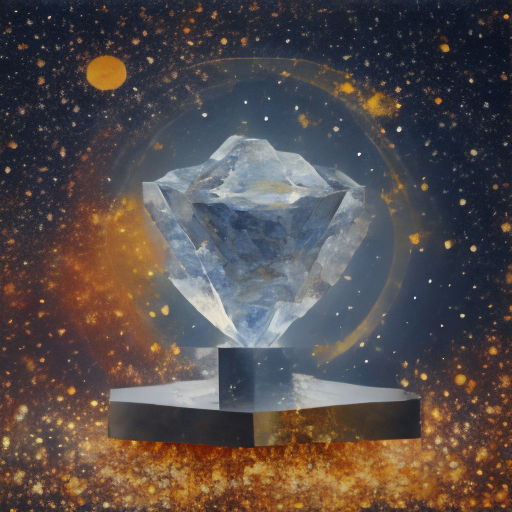

In [5]:
# Первый контрольный запуск: PNG и JSON создаются одним вызовом.
from IPython.display import display
manifest_1 = generate("run_001")
display(Image.open("artifacts/run_001/result.png"))


In [6]:
# Независимая формальная валидация первого запуска.
HEX = set("0123456789abcdef")
png_1 = Path("artifacts/run_001/result.png")
loaded_1 = json.loads(Path("artifacts/run_001/manifest.json").read_text(encoding="utf-8"))
actual_sha_1 = hashlib.sha256(png_1.read_bytes()).hexdigest()
with Image.open(png_1) as im:
    observed_size, observed_mode = im.size, im.mode
    im.verify()

config_keys = ["variant", "model_id", "revision", "prompt", "seed",
               "num_inference_steps", "guidance_scale", "height", "width"]
assert all(loaded_1[k] == CONFIG[k] for k in config_keys)
assert observed_size == (512, 512) and observed_mode == "RGB"
assert len(actual_sha_1) == 64 and set(actual_sha_1) <= HEX
assert actual_sha_1 == loaded_1["sha256"]

print("JSON валиден              PASS")
print("конфиг совпадает          PASS")
print("PNG 512x512 / RGB         PASS")
print("SHA-256 пересчитан        PASS")
print(actual_sha_1)


JSON валиден              PASS
конфиг совпадает          PASS
PNG 512x512 / RGB         PASS
SHA-256 пересчитан        PASS
590b9e700294e5a950c224221070181f9ab1dc193f9a016f8b388a07762a8ced


## 5. Результат и соответствие варианту

Центральный прозрачный кристалл читается как условный исследуемый объект; орбитальные
дуги и частицы задают тему открытия без имитации диаграммы. Сине-янтарная палитра
соответствует prompt, композиция центрирована.

Главный критерий варианта выполнен: в финальном изображении нет читаемого или
псевдочитаемого текста, подписей, логотипов и водяных знаков. Пилот с формулировкой
`concept poster` создавал псевдотекст, поэтому финальный prompt использует
`square key visual`, `full-bleed` и `borderless`.

Изображение является учебным концептом. Оно не представляет реальный экспонат,
не является научной схемой и не подтверждает фактические данные.


In [7]:
# Шаг 4: точный повтор без изменения CONFIG и независимое сравнение.
manifest_2 = generate("run_002")
png_2 = Path("artifacts/run_002/result.png")
loaded_2 = json.loads(Path("artifacts/run_002/manifest.json").read_text(encoding="utf-8"))
actual_sha_2 = hashlib.sha256(png_2.read_bytes()).hexdigest()
assert actual_sha_2 == loaded_2["sha256"]
assert all(loaded_2[k] == CONFIG[k] for k in config_keys)

comparison = {
    "checked_utc": datetime.now(timezone.utc).isoformat(),
    "device": DEVICE,
    "dtype": str(DTYPE),
    "platform": platform.platform(),
    "run_001_sha256": actual_sha_1,
    "run_002_sha256": actual_sha_2,
    "exact_sha256_match": actual_sha_1 == actual_sha_2,
    "generation_seconds": {
        "run_001": loaded_1["generation_seconds_measured"],
        "run_002": loaded_2["generation_seconds_measured"],
    },
    "visual_no_text_manual": True,
    "interpretation": ("PASS: два запуска в этой зафиксированной среде "
                       "совпали побитово; визуальная проверка текста пройдена."),
}
Path("reports/sha256_comparison.json").write_text(
    json.dumps(comparison, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(json.dumps(comparison, ensure_ascii=False, indent=2))
assert comparison["exact_sha256_match"] is True


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:36<00:00, 36.42s/it]

100%|██████████| 1/1 [00:36<00:00, 36.45s/it]

run_002: (512, 512), RGB, 77.067 с
SHA-256: 590b9e700294e5a950c224221070181f9ab1dc193f9a016f8b388a07762a8ced
{
  "checked_utc": "2026-09-22T07:36:15.709846+00:00",
  "device": "cpu",
  "dtype": "torch.float32",
  "platform": "Windows-10-10.0.26200-SP0",
  "run_001_sha256": "590b9e700294e5a950c224221070181f9ab1dc193f9a016f8b388a07762a8ced",
  "run_002_sha256": "590b9e700294e5a950c224221070181f9ab1dc193f9a016f8b388a07762a8ced",
  "exact_sha256_match": true,
  "generation_seconds": {
    "run_001": 83.269369799993,
    "run_002": 77.06672289999551
  },
  "visual_no_text_manual": true,
  "interpretation": "PASS: два запуска в этой зафиксированной среде совпали побитово; визуальная проверка текста пройдена."
}


## 6. Намеренно введённая типовая ошибка

Ошибка воспроизводится в безопасной копии кода: вместо CPU Generator жёстко
задаётся CUDA, хотя фактическая сборка PyTorch не поддерживает CUDA. Отказ должен
возникнуть на строке создания Generator — до инференса — и не повредить успешные
артефакты.


In [8]:
# Шаг 5: типовая ошибка на безопасной копии кода.
import shutil
BROKEN_DEVICE = "cuda" if not torch.cuda.is_available() else "cuda:7"
print(f"cuda_available={torch.cuda.is_available()}, pipeline={DEVICE}")
print(f"сломанный Generator: {BROKEN_DEVICE}\n")
Path("artifacts/error_demo_incomplete").mkdir(exist_ok=True)
try:
    torch.Generator(device=BROKEN_DEVICE).manual_seed(CONFIG["seed"])
    print("Ошибка не воспроизвелась — этот факт следовало бы сохранить как есть.")
except Exception as exc:
    print("=== СИМПТОМ ===")
    print(f"{type(exc).__name__}: {str(exc)[:300]}")
    print("\n=== ДИАГНОСТИКА ===")
    print("torch.cuda.is_available() =", torch.cuda.is_available())
    print("torch.cuda.device_count() =", torch.cuda.device_count())
    print("отказ произошёл на создании Generator, до вызова pipeline")
    print("\n=== ИСПРАВЛЕНИЕ ===")
    print("torch.Generator(device='cpu').manual_seed(SEED)")
    print("или выбирать устройство только после проверки доступности")
finally:
    shutil.rmtree("artifacts/error_demo_incomplete", ignore_errors=True)
    print("\nнеполный каталог удалён")


cuda_available=False, pipeline=cpu
сломанный Generator: cuda

=== СИМПТОМ ===
RuntimeError: Device type CUDA is not supported for torch.Generator() api.

=== ДИАГНОСТИКА ===
torch.cuda.is_available() = False
torch.cuda.device_count() = 0
отказ произошёл на создании Generator, до вызова pipeline

=== ИСПРАВЛЕНИЕ ===
torch.Generator(device='cpu').manual_seed(SEED)
или выбирать устройство только после проверки доступности

неполный каталог удалён


## 7. Ограничения и угрозы валидности

1. Проверена одна конфигурация: вывод не переносится на другие prompt и seed.
2. Побитовое совпадение доказано только внутри одной среды; CPU и GPU могут дать
   визуально эквивалентные, но разные байты.
3. Использован Transformers 5.x вместо неразрешимого диапазона из методички.
4. Pipeline загружен без safety checker; публичный сервис не создавался.
5. Ограничение `no text` снижает вероятность текста, но не гарантирует её — поэтому
   выполнена ручная визуальная проверка.
6. SHA-256 проверяет целостность и равенство байтов, но не качество изображения.

| Угроза | Контрмера |
| --- | --- |
| Манифест содержит ожидания, а не наблюдения | размер, режим и hash прочитаны из сохранённого PNG |
| Второй результат просто скопирован | функция генерации вызвана повторно, времена различаются |
| Псевдотекст скрыт формальной проверкой | результат показан прямо в ноутбуке и оценён визуально |
| Концепт выдан за научную визуализацию | граница смысла записана в prompt и отчёте |

Визуально эквивалентный, но побитово другой результат допустим для мудборда или
эскиза, но недостаточен для регрессионного теста и доказательства происхождения.


## 8. Вывод и чек-лист

Цель достигнута: SD-Turbo запущена локально с полной revision, два PNG созданы
независимыми вызовами и совпали по SHA-256, манифесты валидны, а вариант 3
выполнен без текста и логотипов. Типовая ошибка воспроизведена и диагностирована.

**Доказано:** побитовое равенство двух конкретных файлов в зафиксированной CPU-среде.  
**Не доказано:** равенство на другой платформе и научная достоверность изображения.

- [x] model_id и полная revision сохранены;
- [x] prompt, seed, steps, guidance, размер, device и dtype зафиксированы;
- [x] `environment.txt` создан после установки;
- [x] PNG и JSON провалидированы;
- [x] SHA-256 совпали;
- [x] результат не выдан за документальный факт;
- [x] кэш весов и `.venv` исключены из репозитория.


## 9. Ответы на контрольные вопросы

**1. Модель, pipeline и приложение.** Модель — веса и архитектура. Pipeline
связывает text encoder, UNet, scheduler и VAE. Приложение добавляет интерфейс,
хранение и политику использования.

**2. Почему имени модели мало.** Оно указывает на изменяемый репозиторий; полная
revision закрепляет снимок файлов.

**3. Что фиксирует seed.** Начальное состояние генератора, но не устройство,
dtype, версии библиотек, порядок операций и веса.

**4. Зачем CPU Generator.** Он не требует CUDA и повышает сопоставимость
начального шума между устройствами; для повтора создаётся заново.

**5. Что доказывает SHA-256.** Побайтовое равенство файлов, но не качество,
корректность или эстетическую ценность.

**6. Почему CPU/GPU могут различаться.** Различаются ядра, арифметика, dtype и
порядок редукций; младшие биты могут изменить PNG.

**7. Зачем dtype и версии.** Они позволяют отличить изменение среды от ошибки кода.

**8. Ограничения варианта.** Prompt авторский, без персональных данных, лиц,
товарных знаков и закрытых материалов; результат не является научной схемой.

**9. Как диагностирована ошибка.** Трассировка указывает на создание CUDA Generator
до pipeline; состояние CUDA сопоставлено с жёстко заданным устройством.

**10. Допустимый вывод.** Результат воспроизводим в этой среде и пригоден как
учебный концепт. Нельзя гарантировать те же байты на любой машине или считать
изображение научным свидетельством.


## 10. Репозиторий и индивидуальный вклад

**Репозиторий:** https://github.com/ykvnkm/ai-in-creative-industries · **работа:** `LR01/`

Самостоятельно выполнены: prompt варианта 3; диагностика псевдотекста пилота;
формальный единый конфиг; два локальных запуска; независимая валидация PNG и JSON;
сравнение SHA-256; фиксация конфликта зависимостей; воспроизведение типовой ошибки;
анализ ограничений и границ воспроизводимости.
